# Análisis exploratorio de datos (fase 2: comprensión de los datos)

Este cuaderno describe las imágenes disponibles para el proyecto y detecta los problemas que deben resolverse en la preparación de datos. Aborda cuatro preguntas: cómo se distribuyen las clases, qué calidad tienen las imágenes, cuántas están repetidas o contradicen su etiqueta y si las diferencias entre clases se explican por algo distinto a la fruta.

**Fuentes analizadas**

| Fuente | Descripción | Etiqueta |
|---|---|---|
| `kaggle` | Conjunto de referencia *Fruit Quality Classification* (versión 1): carpetas Good, Bad y Mixed | Carpeta (Mixed no tiene clase por imagen) |
| `companeros` | Imágenes compartidas por otros grupos del curso, organizadas por calidad (`good`, `regular`, `bad`) y fruta | Carpeta |
| `propias_etiquetadas` | Muestra de 144 imágenes con carpetas de calidad y fruta | Carpeta |
| `propias_sin_clasificar` | Fotos tomadas por el grupo, sin clasificar; la clase proviene de una preetiqueta provisional | Preetiqueta provisional |

**Alcance.** El cuaderno solo lee las imágenes y no las modifica. Las imágenes de otros grupos no se versionan en este repositorio y no se reproducen en las figuras; las figuras se calculan a partir del inventario `data/processed/inventario.csv`, que se genera con `python -m src.data.inventario` (ver [`src/data/inventario.py`](../src/data/inventario.py)).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

AQUI = Path.cwd().resolve()
REPO = AQUI if (AQUI / "src").exists() else AQUI.parent
sys.path.insert(0, str(REPO))
import src.data.inventario  # registra el lector de imágenes HEIC

FIGURAS = REPO / "2_comprension_datos" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
INVENTARIO = REPO / "data" / "processed" / "inventario.csv"

ORDEN_CAL = ["buena", "regular", "mala"]
ORDEN_FRUTA = ["manzana", "banano", "guayaba", "limon", "naranja", "granada"]
COLOR_CAL = {"buena": "#4C9F70", "regular": "#E0A526", "mala": "#C8553D"}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})


def guardar(fig, nombre):
    fig.savefig(FIGURAS / f"{nombre}.png", dpi=130, bbox_inches="tight")


inv = pd.read_csv(INVENTARIO)
inv["calidad"] = pd.Categorical(inv["calidad"], ORDEN_CAL + ["mezclada", "multiple"])
print(f"{len(inv):,} imágenes catalogadas en {inv['origen'].nunique()} fuentes")

29,486 imágenes catalogadas en 4 fuentes


## 1. Fuentes y tamaño del conjunto

Se compara cada fuente por número de imágenes, peso en disco y resolución. La columna de duplicados exactos cuenta archivos con contenido idéntico (hash MD5) a otro catalogado antes.

In [2]:
resumen = inv.groupby("origen").agg(
    imagenes=("archivo", "size"),
    duplicados_exactos=("duplicado_exacto", "sum"),
    peso_MB=("bytes", lambda s: round(s.sum() / 1e6)),
    lado_mayor_mediana=("lado_mayor", "median"),
    lado_mayor_min=("lado_mayor", "min"),
    lado_mayor_max=("lado_mayor", "max"),
)
display(resumen)

etiquetadas = inv[inv["origen"] == "propias_etiquetadas"]
print(f"Imágenes de 'propias_etiquetadas' que ya están (contenido idéntico) en otra fuente: "
      f"{int(etiquetadas['duplicado_exacto'].sum())} de {len(etiquetadas)}")
print(f"Imágenes ilegibles: {int((inv['lado_mayor'] < 0).sum())}")

,imagenes,duplicados_exactos,peso_MB,lado_mayor_mediana,lado_mayor_min,lado_mayor_max
origen,,,,,,
companeros,9515,33,3468,538.0,16,4032
kaggle,19526,0,3291,256.0,256,8000
propias_etiquetadas,144,144,62,1440.0,28,4032
propias_sin_clasificar,301,1,969,5712.0,4032,5712


Imágenes de 'propias_etiquetadas' que ya están (contenido idéntico) en otra fuente: 144 de 144
Imágenes ilegibles: 0


Las 144 imágenes de `propias_etiquetadas` están contenidas en `companeros`, de modo que no aportan datos nuevos. En lo que sigue, el análisis usa solo **imágenes únicas** (se descartan los duplicados exactos, conservando la primera aparición).

In [3]:
unicos = inv[~inv["duplicado_exacto"]].copy()
comp = unicos[unicos["origen"] == "companeros"].copy()
comp["calidad"] = pd.Categorical(comp["calidad"].astype(str), ORDEN_CAL)
print(f"Imágenes únicas: {len(unicos):,} (companeros: {len(comp):,})")

Imágenes únicas: 29,308 (companeros: 9,482)


## 2. Distribución de clases

Se cuenta la cantidad de imágenes por calidad y fruta, y qué tan desbalanceadas están las clases.

calidad,buena,regular,mala,total
fruta,,,,
manzana,267,890,153,1310
banano,201,936,684,1821
guayaba,200,810,135,1145
limon,200,743,152,1095
naranja,206,510,111,827
granada,1555,720,1009,3284
total,2629,4609,2244,9482


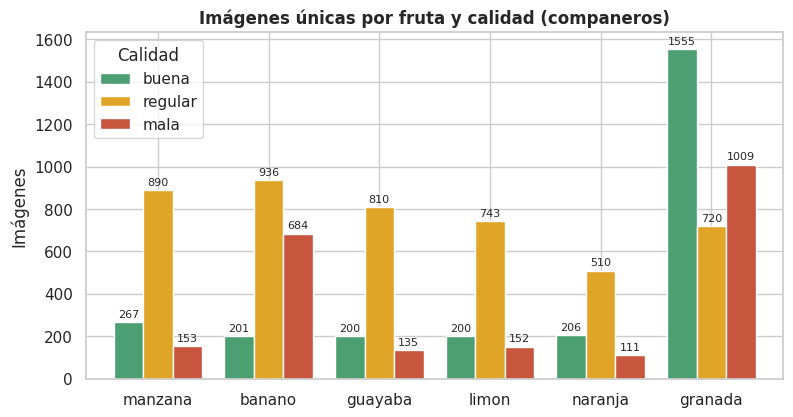

In [4]:
tabla = (comp.pivot_table(index="fruta", columns="calidad", values="archivo",
                          aggfunc="size", observed=True)
         .reindex(ORDEN_FRUTA)[ORDEN_CAL])
tabla["total"] = tabla.sum(axis=1)
tabla.loc["total"] = tabla.sum()
display(tabla)

fig, ax = plt.subplots(figsize=(9, 4.5))
tabla.drop(index="total", columns="total").plot(
    kind="bar", ax=ax, width=0.8, color=[COLOR_CAL[c] for c in ORDEN_CAL])
for cont in ax.containers:
    ax.bar_label(cont, fontsize=8, padding=2)
ax.set(title="Imágenes únicas por fruta y calidad (companeros)", xlabel="", ylabel="Imágenes")
ax.legend(title="Calidad")
plt.xticks(rotation=0)
guardar(fig, "01_clases_por_fruta")
plt.show()

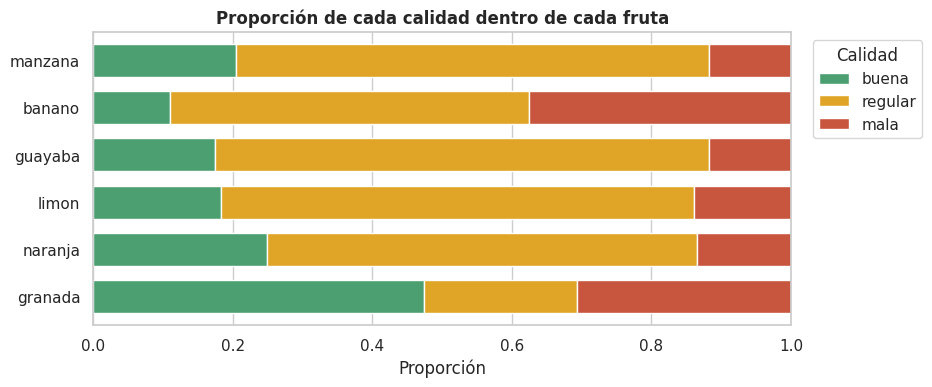

,clase_mayor/clase_menor,% del total de imágenes
fruta,,
manzana,5.8,13.8
banano,4.7,19.2
guayaba,6.0,12.1
limon,4.9,11.5
naranja,4.6,8.7
granada,2.2,34.6


In [5]:
base_tabla = tabla.drop(index="total", columns="total")
proporcion = base_tabla.div(base_tabla.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(9, 3.8))
proporcion.plot(kind="barh", stacked=True, ax=ax, width=0.7,
                color=[COLOR_CAL[c] for c in ORDEN_CAL])
ax.set(title="Proporción de cada calidad dentro de cada fruta", xlabel="Proporción", ylabel="")
ax.set_xlim(0, 1)
ax.legend(title="Calidad", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.invert_yaxis()
guardar(fig, "02_proporcion_clases")
plt.show()

razon = (base_tabla.max(axis=1) / base_tabla.min(axis=1)).round(1)
participacion = (base_tabla.sum(axis=1) / base_tabla.values.sum() * 100).round(1)
display(pd.DataFrame({"clase_mayor/clase_menor": razon, "% del total de imágenes": participacion}))

### 2.1 Conjunto de Kaggle

Las carpetas Good y Bad corresponden a las clases buena y mala. La carpeta Mixed no tiene una clase por imagen: contiene fotos con varias frutas de calidades distintas que deben segmentarse. Kaggle no incluye una clase Regular.

calidad,Good,Bad,Mixed,total
fruta,,,,
manzana,1149,1141,113,2403
banano,1113,1087,285,2485
guayaba,1152,1129,148,2429
limon,1094,1085,278,2457
naranja,1216,1159,125,2500
granada,5940,1187,125,7252
total,11664,6788,1074,19526


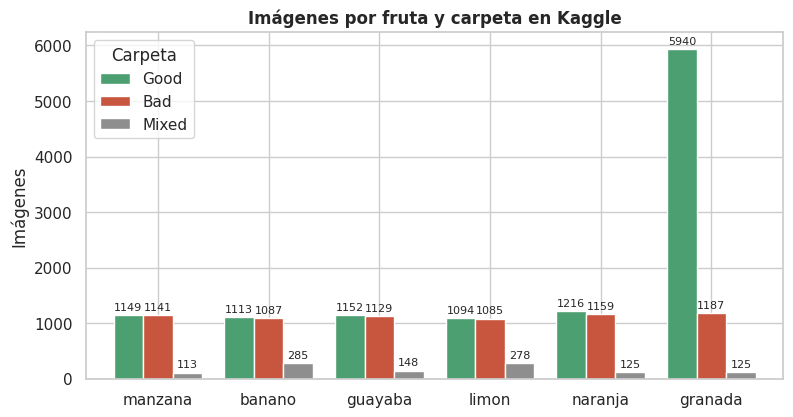

In [6]:
kag = unicos[unicos["origen"] == "kaggle"].copy()
kag["calidad"] = pd.Categorical(kag["calidad"].astype(str), ["buena", "mala", "mezclada"])
tabla_kaggle = (kag.pivot_table(index="fruta", columns="calidad", values="archivo",
                                aggfunc="size", observed=True)
                .reindex(ORDEN_FRUTA).rename(columns={"buena": "Good", "mala": "Bad", "mezclada": "Mixed"}))
tabla_kaggle["total"] = tabla_kaggle.sum(axis=1)
tabla_kaggle.loc["total"] = tabla_kaggle.sum()
display(tabla_kaggle)

fig, ax = plt.subplots(figsize=(9, 4.5))
tabla_kaggle.drop(index="total", columns="total").plot(
    kind="bar", ax=ax, width=0.8, color=[COLOR_CAL["buena"], COLOR_CAL["mala"], "#8E8E8E"])
for cont in ax.containers:
    ax.bar_label(cont, fontsize=8, padding=2)
ax.set(title="Imágenes por fruta y carpeta en Kaggle", xlabel="", ylabel="Imágenes")
ax.legend(title="Carpeta")
plt.xticks(rotation=0)
guardar(fig, "09_kaggle_clases")
plt.show()

Las imágenes preetiquetadas del grupo (`propias_sin_clasificar`) todavía no tienen una clase confirmada. Se muestran por separado, junto con las que contienen varias frutas y requieren segmentación.

In [7]:
propias = inv[inv["origen"] == "propias_sin_clasificar"].copy()
propias["calidad"] = propias["calidad"].astype(object).fillna("sin preetiqueta (duplicado)")
tabla_propias = propias.pivot_table(index="fruta", columns="calidad", values="archivo",
                                    aggfunc="size", fill_value=0)
display(tabla_propias)
print(f"Total: {len(propias)} archivos; únicos por contenido exacto: "
      f"{int((~propias['duplicado_exacto']).sum())}")

calidad,buena,multiple,regular
fruta,,,
banano,0,45,0
citricos,0,3,0
limon,25,16,0
manzana,64,12,0
naranja,7,0,10


Total: 301 archivos; únicos por contenido exacto: 300


## 3. Calidad de las imágenes

### 3.1 Resolución

Se usa como referencia el lado de 224 píxeles, tamaño de entrada habitual de las redes convolucionales preentrenadas. No es un criterio fijado para el proyecto: sirve para dimensionar cuántas imágenes quedarían sobre-ampliadas.

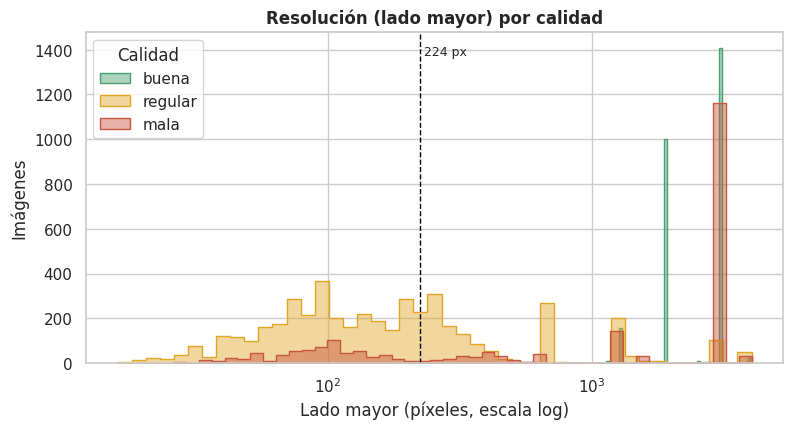

,mediana,minimo,maximo,% < 224 px,% < 128 px
calidad,,,,,
buena,3120.0,1132,4032,0.0,0.0
regular,146.0,16,4032,65.6,44.9
mala,2992.0,26,4032,28.6,22.5


In [8]:
fig, ax = plt.subplots(figsize=(9, 4.3))
for cal in ORDEN_CAL:
    sns.histplot(comp.loc[comp["calidad"] == cal, "lado_mayor"], log_scale=True, bins=45,
                 element="step", alpha=0.45, color=COLOR_CAL[cal], label=cal, ax=ax)
ax.axvline(224, color="black", ls="--", lw=1)
ax.text(232, ax.get_ylim()[1] * 0.93, "224 px", fontsize=9)
ax.set(title="Resolución (lado mayor) por calidad", xlabel="Lado mayor (píxeles, escala log)",
       ylabel="Imágenes")
ax.legend(title="Calidad")
guardar(fig, "03_resolucion_por_calidad")
plt.show()

res = comp.groupby("calidad", observed=True)["lado_mayor"].agg(
    mediana="median", minimo="min", maximo="max")
res["% < 224 px"] = comp.groupby("calidad", observed=True)["lado_mayor"].apply(lambda s: (s < 224).mean() * 100).round(1)
res["% < 128 px"] = comp.groupby("calidad", observed=True)["lado_mayor"].apply(lambda s: (s < 128).mean() * 100).round(1)
display(res.loc[ORDEN_CAL])

### 3.2 Origen aparente de los archivos

El nombre del archivo permite distinguir tres tipos: **capturas de pantalla** (`Captura de pantalla…`, `Screen Shot…`), **imágenes aumentadas** (`…_aug_N`, `rotated_by_N…`, versiones rotadas o recortadas de otra imagen) y **originales** (el resto). Las capturas y las imágenes aumentadas no son fotografías directas de una fruta.

tipo_archivo,aumentada,captura,original
calidad,,,
buena,0,0,2629
regular,173,1765,2671
mala,377,77,1790


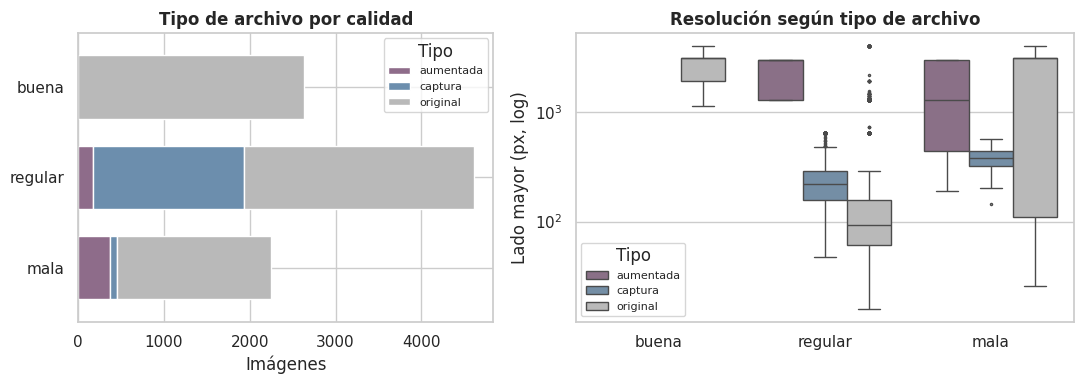

Regular, tipo 'original': 2,671 imágenes; mediana de lado mayor = 93 px; 79 % por debajo de 224 px


In [9]:
tipo = pd.crosstab(comp["calidad"], comp["tipo_archivo"]).loc[ORDEN_CAL]
display(tipo)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.2]})
tipo.plot(kind="barh", stacked=True, ax=axes[0], width=0.7,
          color=["#8E6C8A", "#6C8EAD", "#B9B9B9"])
axes[0].set(title="Tipo de archivo por calidad", xlabel="Imágenes", ylabel="")
axes[0].invert_yaxis()
axes[0].legend(title="Tipo", fontsize=8)

sns.boxplot(data=comp, x="calidad", y="lado_mayor", hue="tipo_archivo", order=ORDEN_CAL,
            hue_order=["aumentada", "captura", "original"],
            palette=["#8E6C8A", "#6C8EAD", "#B9B9B9"], fliersize=1.5, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set(title="Resolución según tipo de archivo", xlabel="", ylabel="Lado mayor (px, log)")
axes[1].legend(title="Tipo", fontsize=8)
plt.tight_layout()
guardar(fig, "04_tipo_archivo")
plt.show()

orig_regular = comp[(comp["calidad"] == "regular") & (comp["tipo_archivo"] == "original")]
print("Regular, tipo 'original': "
      f"{len(orig_regular):,} imágenes; mediana de lado mayor = {orig_regular['lado_mayor'].median():.0f} px; "
      f"{(orig_regular['lado_mayor'] < 224).mean() * 100:.0f} % por debajo de 224 px")

### 3.3 Resolución por fuente

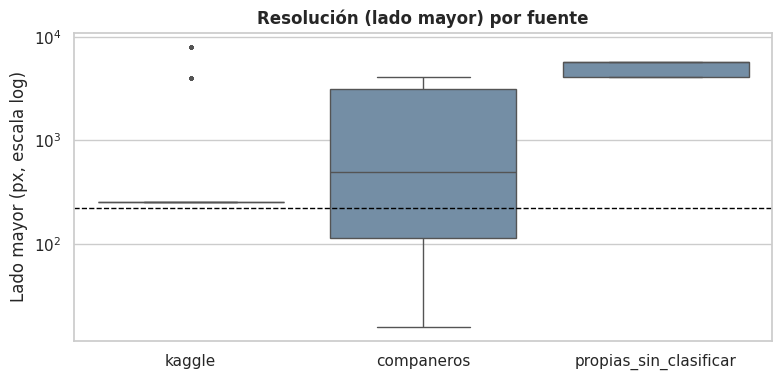

,mediana,minimo,maximo,% < 224 px
origen,,,,
kaggle,256.0,256,8000,0.0
companeros,491.0,16,4032,38.7
propias_sin_clasificar,5712.0,4032,5712,0.0


calidad,buena,mala,mezclada
row_0,,,
192×256,1193,2775,568
256×192,864,527,506
256×256,9043,3465,0
3000×4000,381,0,0
8000×6000,183,0,0
otro,0,21,0


,,imágenes con lado mayor de 1000 px o más
fruta,calidad,
granada,buena,564


In [10]:
orden_fuentes = ["kaggle", "companeros", "propias_sin_clasificar"]
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=unicos, x="origen", y="lado_mayor", order=orden_fuentes, color="#6C8EAD",
            fliersize=1.5, ax=ax)
ax.set_yscale("log")
ax.axhline(224, color="black", ls="--", lw=1)
ax.set(title="Resolución (lado mayor) por fuente", xlabel="", ylabel="Lado mayor (px, escala log)")
guardar(fig, "10_resolucion_por_fuente")
plt.show()

por_fuente = unicos.groupby("origen")["lado_mayor"].agg(mediana="median", minimo="min", maximo="max")
por_fuente["% < 224 px"] = unicos.groupby("origen")["lado_mayor"].apply(lambda s: (s < 224).mean() * 100).round(1)
display(por_fuente.loc[orden_fuentes])
tamanos = kag["ancho"].astype(str) + "×" + kag["alto"].astype(str)
principales = tamanos.value_counts().nlargest(5).index
display(pd.crosstab(tamanos.where(tamanos.isin(principales), "otro"), kag["calidad"]))
display(kag[kag["lado_mayor"] >= 1000].groupby(["fruta", "calidad"], observed=True).size().rename("imágenes con lado mayor de 1000 px o más").to_frame())

## 4. Duplicados y etiquetas contradictorias

El hash MD5 detecta archivos idénticos byte a byte. Esto **no** detecta fotos distintas del mismo ejemplar ni versiones recortadas o rotadas (duplicados aproximados), que requerirían un hash perceptual y que deberán agruparse antes de dividir en entrenamiento y prueba.

,total,duplicados,unicas
origen,,,
companeros,9515,33,9482
kaggle,19526,0,19526
propias_etiquetadas,144,144,0
propias_sin_clasificar,301,1,300


Grupos de archivos idénticos: 174; con calidades distintas: 3; con frutas distintas: 0
Grupos idénticos entre Kaggle y otra fuente: 0


,origen,ruta,fruta,calidad
20404,companeros,bad/Guava_Bad/Guava_Bad/guava_bad18_aug_9.jpg,guayaba,mala
20406,companeros,bad/Guava_Bad/Guava_Bad/guava_bad19_aug_6.jpg,guayaba,mala
20407,companeros,bad/Guava_Bad/Guava_Bad/guava_bad19_aug_7.jpg,guayaba,mala
26975,companeros,regular/Guava_Regular/Guava_Regular/guava_bad1...,guayaba,regular
26978,companeros,regular/Guava_Regular/Guava_Regular/guava_bad1...,guayaba,regular
26979,companeros,regular/Guava_Regular/Guava_Regular/guava_bad1...,guayaba,regular


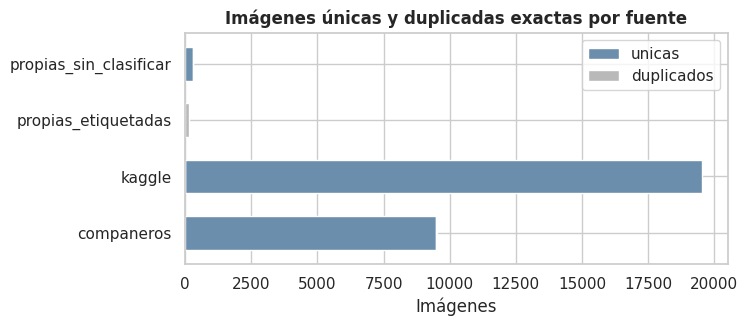

In [11]:
dup = inv.groupby("origen").agg(total=("archivo", "size"), duplicados=("duplicado_exacto", "sum"))
dup["unicas"] = dup["total"] - dup["duplicados"]
display(dup)

con_hash = inv[inv["md5"].notna()]
grupos = con_hash.groupby("md5").agg(
    archivos=("archivo", "size"), calidades=("calidad", lambda s: s.dropna().nunique()),
    frutas=("fruta", lambda s: s.dropna().nunique()), origenes=("origen", "nunique"))
grupos = grupos[grupos["archivos"] > 1]
print(f"Grupos de archivos idénticos: {len(grupos)}; "
      f"con calidades distintas: {int((grupos['calidades'] > 1).sum())}; "
      f"con frutas distintas: {int((grupos['frutas'] > 1).sum())}")

entre_fuentes = con_hash.groupby("md5")["origen"].agg(set)
print("Grupos idénticos entre Kaggle y otra fuente:",
      int(entre_fuentes.map(lambda o: "kaggle" in o and len(o) > 1).sum()))

conflictos = con_hash[con_hash["md5"].isin(grupos.index[grupos["calidades"] > 1])]
display(conflictos[["origen", "ruta", "fruta", "calidad"]].sort_values("ruta"))

fig, ax = plt.subplots(figsize=(7, 3))
dup[["unicas", "duplicados"]].plot(kind="barh", stacked=True, ax=ax, width=0.6,
                                   color=["#6C8EAD", "#B9B9B9"])
ax.set(title="Imágenes únicas y duplicadas exactas por fuente", xlabel="Imágenes", ylabel="")
guardar(fig, "05_duplicados")
plt.show()

## 5. Variabilidad visual y sesgo por fuente

Se calculan estadísticas de color sobre una muestra estratificada (hasta 60 imágenes por combinación de fuente, fruta y calidad): brillo medio, saturación media, brillo del borde de la imagen y desviación de color en el borde (a menor desviación, fondo más uniforme).

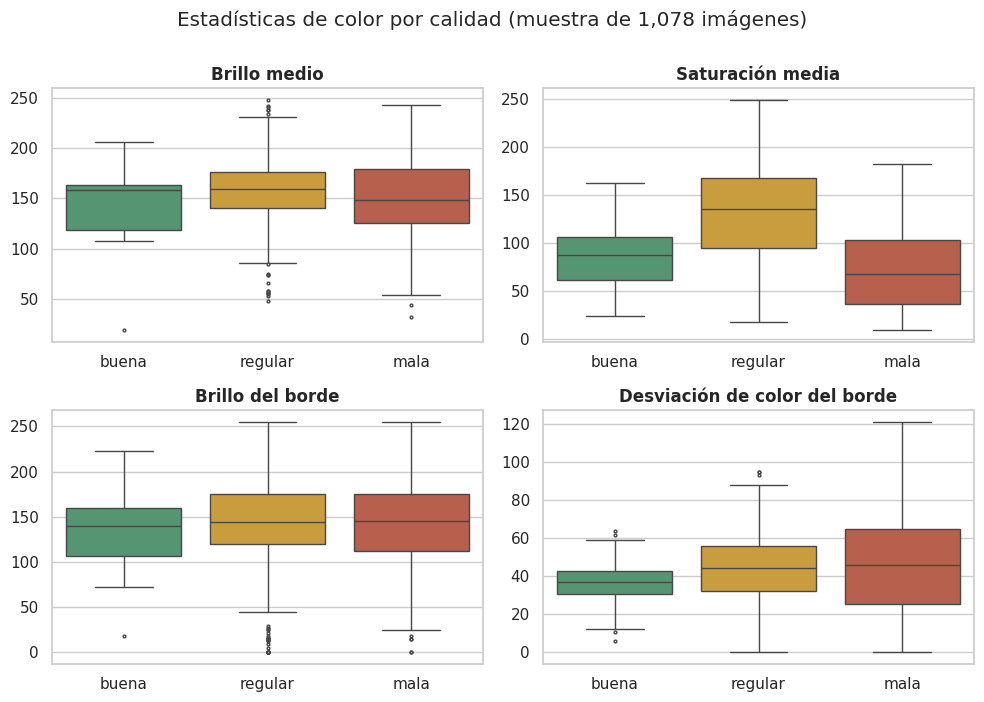

,brillo,saturacion,brillo_borde,desv_borde
calidad,,,,
buena,158.6,86.9,140.2,37.0
regular,159.1,135.3,144.0,44.3
mala,148.7,67.4,145.3,46.0


In [12]:
muestra = comp[comp["brillo"].notna()]
variables = {"brillo": "Brillo medio", "saturacion": "Saturación media",
             "brillo_borde": "Brillo del borde", "desv_borde": "Desviación de color del borde"}
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, (col, titulo) in zip(axes.ravel(), variables.items()):
    sns.boxplot(data=muestra, x="calidad", y=col, order=ORDEN_CAL, hue="calidad",
                palette=COLOR_CAL, legend=False, fliersize=2, ax=ax)
    ax.set(title=titulo, xlabel="", ylabel="")
fig.suptitle(f"Estadísticas de color por calidad (muestra de {len(muestra):,} imágenes)", y=1.0)
plt.tight_layout()
guardar(fig, "06_color_por_calidad")
plt.show()
display(muestra.groupby("calidad", observed=True)[list(variables)].median().round(1).loc[ORDEN_CAL])

### 5.1 ¿Se puede predecir la calidad sin mirar la fruta?

Si unos pocos metadatos del archivo (ancho, alto, peso y formato) bastan para acertar la calidad, la etiqueta está confundida con la fuente de la imagen y un modelo podría aprender la fuente en lugar de la fruta. Se entrena un árbol de decisión de profundidad 4 con validación cruzada de 5 particiones y se compara con predecir siempre la clase mayoritaria. La prueba es indicativa: las imágenes casi idénticas entre particiones pueden inflar la exactitud.

companeros


,imágenes,exactitud clase mayoritaria,exactitud solo con metadatos
subconjunto,,,
todas las frutas,9482,0.486,0.788
manzana,1310,0.679,0.953
banano,1821,0.514,0.693
guayaba,1145,0.707,0.940
limon,1095,0.679,0.940
naranja,827,0.617,0.937
granada,3284,0.474,0.747


kaggle (Good y Bad)


,imágenes,exactitud clase mayoritaria,exactitud solo con metadatos
subconjunto,,,
todas las frutas,18452,0.632,0.724
manzana,2290,0.502,0.841
banano,2200,0.506,0.816
guayaba,2281,0.505,0.826
limon,2179,0.502,0.889
naranja,2375,0.512,0.719
granada,7127,0.833,0.910


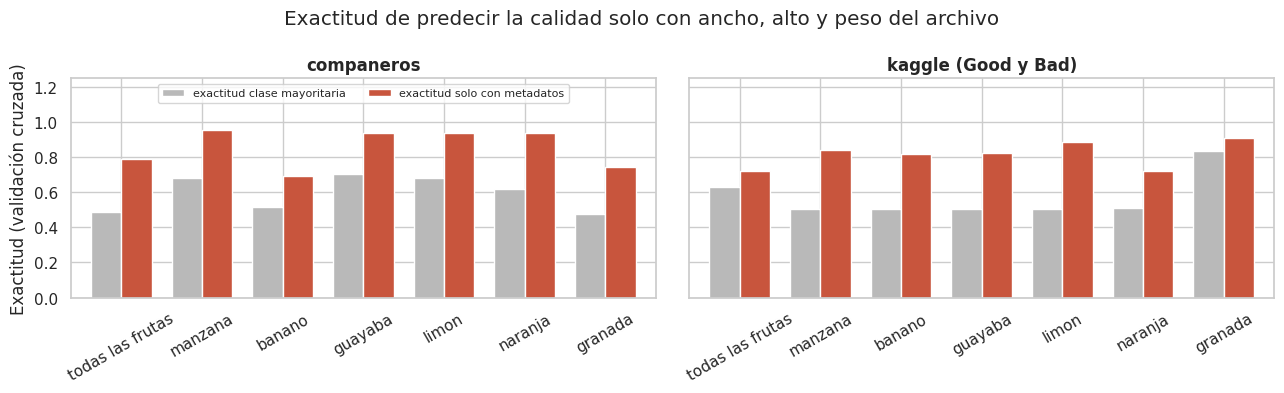

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier

cv = StratifiedKFold(5, shuffle=True, random_state=0)


def exactitud_metadatos(datos):
    filas = []
    subconjuntos = [("todas las frutas", datos.index)]
    subconjuntos += [(f, datos.index[datos["fruta"] == f]) for f in ORDEN_FRUTA]
    for nombre, idx in subconjuntos:
        X = datos.loc[idx, ["ancho", "alto", "bytes"]]
        y = datos.loc[idx, "calidad"].astype(str)
        base = cross_val_score(DummyClassifier(strategy="most_frequent"), X, y, cv=cv).mean()
        meta = cross_val_score(DecisionTreeClassifier(max_depth=4, random_state=0), X, y, cv=cv).mean()
        filas.append({"subconjunto": nombre, "imágenes": len(idx),
                      "exactitud clase mayoritaria": round(base, 3),
                      "exactitud solo con metadatos": round(meta, 3)})
    return pd.DataFrame(filas).set_index("subconjunto")


sesgo = {"companeros": exactitud_metadatos(comp),
         "kaggle (Good y Bad)": exactitud_metadatos(kag[kag["calidad"].isin(["buena", "mala"])])}
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (nombre, tabla_sesgo) in zip(axes, sesgo.items()):
    print(nombre)
    display(tabla_sesgo)
    tabla_sesgo[["exactitud clase mayoritaria", "exactitud solo con metadatos"]].plot(
        kind="bar", ax=ax, color=["#B9B9B9", "#C8553D"], width=0.75, legend=False)
    ax.set(title=nombre, xlabel="", ylim=(0, 1.25))
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Exactitud (validación cruzada)")
axes[0].legend(fontsize=8, loc="upper center", ncol=2)
fig.suptitle("Exactitud de predecir la calidad solo con ancho, alto y peso del archivo")
plt.tight_layout()
guardar(fig, "07_sesgo_metadatos")
plt.show()

### 5.2 Comparación entre fuentes

Se comparan las mismas estadísticas de color entre fuentes. Si las fuentes difieren mucho en iluminación o fondo, un modelo entrenado con una puede fallar con otra (cambio de dominio).

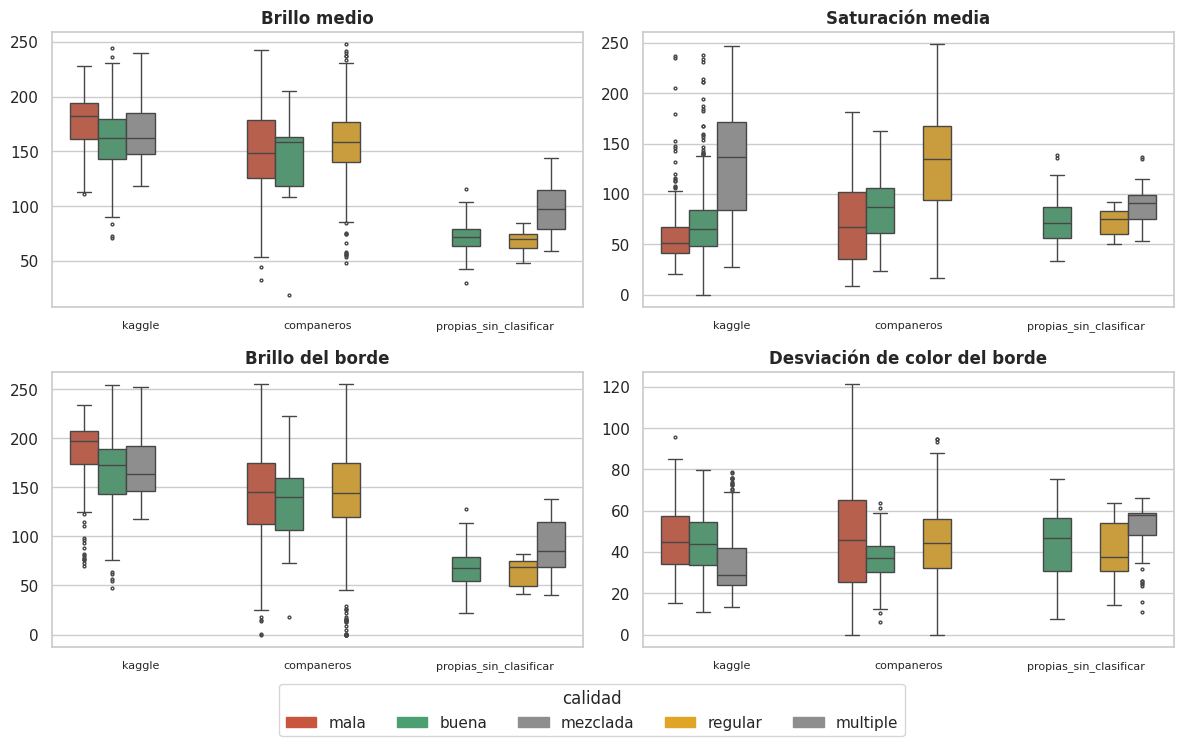

brillo  saturacion  brillo_borde  desv_borde
origen                 calidad                                               
companeros             buena      158.6        86.9         140.2        37.0
                       mala       148.7        67.4         145.3        46.0
                       regular    159.1       135.3         144.0        44.3
kaggle                 buena      162.2        65.8         172.4        43.7
                       mala       182.1        51.5         196.8        45.1
                       mezclada   162.5       136.9         163.1        28.6
propias_sin_clasificar buena       71.5        71.6          67.8        46.7
                       multiple    97.8        90.8          85.2        57.8
                       regular     70.1        75.2          68.7        37.4

In [14]:
from matplotlib.patches import Patch

estadisticas = unicos[unicos["brillo"].notna() & unicos["calidad"].notna()].assign(calidad=lambda d: d["calidad"].astype(str))
colores = {**COLOR_CAL, "mezclada": "#8E8E8E", "multiple": "#8E8E8E"}
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for i, (ax, (col, titulo)) in enumerate(zip(axes.ravel(), variables.items())):
    sns.boxplot(data=estadisticas, x="origen", y=col, hue="calidad", order=orden_fuentes,
                palette=colores, fliersize=2, legend=False, ax=ax)
    ax.set(title=titulo, xlabel="", ylabel="")
    ax.tick_params(axis="x", labelsize=8)
fig.legend(handles=[Patch(color=colores[c], label=c) for c in estadisticas["calidad"].unique()],
           loc="lower center", ncol=5, title="calidad")
plt.tight_layout(rect=(0, 0.07, 1, 1))
guardar(fig, "11_color_por_fuente")
plt.show()
display(estadisticas.groupby(["origen", "calidad"])[list(variables)].median().round(1))

## 6. Muestra de las fotos propias del grupo

Muestra aleatoria de fotos del grupo (`propias_sin_clasificar`), con la fruta y la calidad provisional. Estas fotos son las únicas que se muestran en el cuaderno, porque son del grupo.

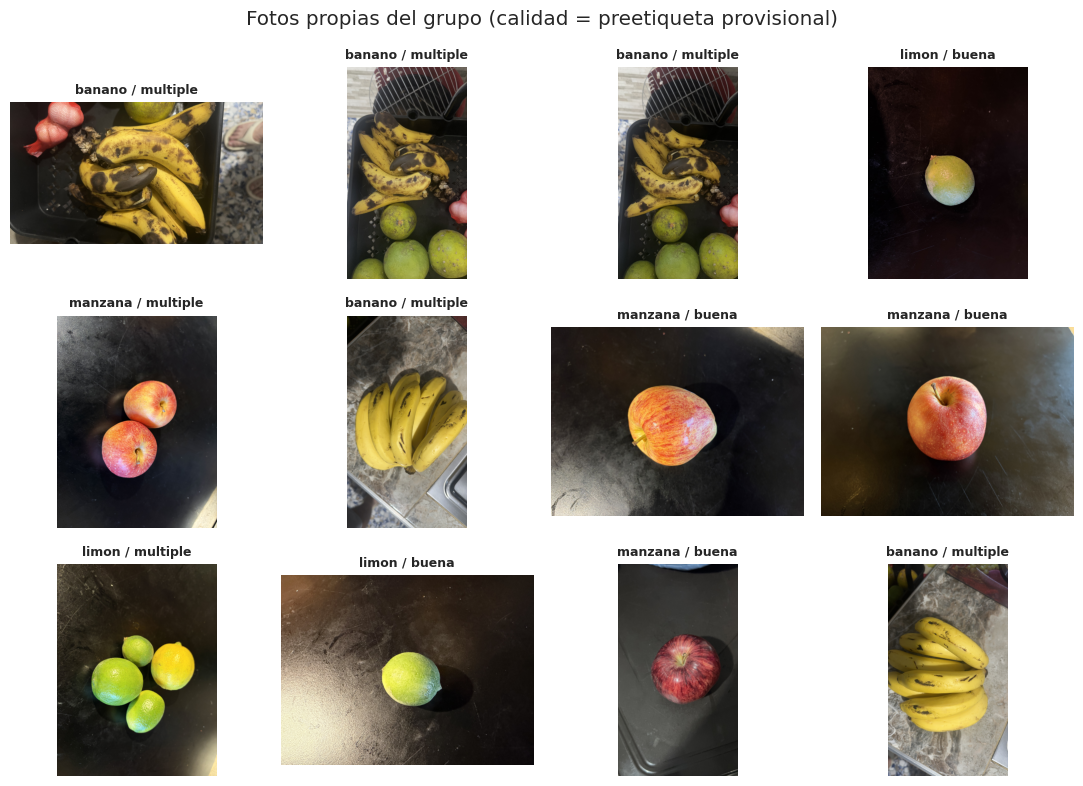

In [15]:
from PIL import Image, ImageOps

grupo = propias[~propias["duplicado_exacto"] & propias["fruta"].notna()]
elegidas = grupo.sample(12, random_state=1)
fig, axes = plt.subplots(3, 4, figsize=(11, 8))
for ax, (_, fila) in zip(axes.ravel(), elegidas.iterrows()):
    with Image.open(fila["ruta_absoluta"]) as im:
        im.draft("RGB", (600, 600))
        ax.imshow(ImageOps.exif_transpose(im).convert("RGB"))
    ax.set_title(f"{fila['fruta']} / {fila['calidad']}", fontsize=9)
    ax.axis("off")
fig.suptitle("Fotos propias del grupo (calidad = preetiqueta provisional)")
plt.tight_layout()
guardar(fig, "08_muestra_propias")
plt.show()

## 7. Hallazgos y decisiones para la preparación de datos

**Hallazgos**

1. **Kaggle tiene 19.526 imágenes: 11.664 Good, 6.788 Bad y 1.074 Mixed, y ninguna Regular.** La granada concentra el 37 % (7.252 imágenes), y las 5.940 imágenes Good de granada son el 51 % de la carpeta Good.
2. **No hay duplicados exactos dentro de Kaggle ni entre Kaggle y las demás fuentes.** Las 144 imágenes de `propias_etiquetadas` son duplicados exactos de imágenes de `companeros`, por lo que no aportan datos nuevos. El conjunto único de `companeros` tiene 9.482 imágenes: 2.629 de calidad buena, 4.609 regular y 2.244 mala.
3. **Las clases están desbalanceadas.** En `companeros` la granada concentra el 34,6 % de las imágenes y, dentro de cada fruta, la clase más numerosa supera entre 2,2 y 6,0 veces a la menos numerosa.
4. **La resolución depende de la fuente y de la clase.** En Kaggle ninguna imagen baja de 224 px, pero 564 imágenes superan los 1.000 px de lado mayor (381 de 3000×4000 y 183 de 8000×6000) y todas son granada de la carpeta Good. En `companeros`, ninguna imagen buena baja de 224 px, pero sí el 65,6 % de las regulares y el 28,6 % de las malas; en Regular, las de tipo original tienen una mediana de 93 px.
5. **El formato también depende de la clase en Kaggle.** El 77,5 % de las imágenes Good miden 256×256, frente al 51,0 % de las Bad, que tienen más imágenes verticales de 192×256 (40,9 %).
6. **Una parte importante de Regular y Mala en `companeros` no son fotografías directas.** Hay 1.842 capturas de pantalla (1.765 en Regular y 77 en Mala) y 550 imágenes aumentadas (173 en Regular y 377 en Mala). Todas las buenas son originales.
7. **Hay etiquetas contradictorias.** Seis archivos de guayaba (tres imágenes `guava_bad…_aug_N`) aparecen idénticos en las carpetas Bad y Regular de `companeros`.
8. **La calidad se puede predecir sin mirar la fruta.** Con solo ancho, alto y peso del archivo, un árbol de decisión alcanza una exactitud de 0,79 en `companeros` frente a 0,49 de la clase mayoritaria. En Kaggle (Good y Bad) alcanza 0,72 frente a 0,63, y entre 0,72 y 0,91 por fruta frente a cerca de 0,50 en las frutas balanceadas. La etiqueta está confundida con la fuente de la imagen en ambos conjuntos.
9. **Hay cambio de dominio entre fuentes.** Las fotos propias son mucho más oscuras (brillo medio de 70 a 98 y brillo del borde de 68 a 85) que las de `companeros` (148 a 159 y 140 a 145) y que las de Kaggle (162 a 182 y 163 a 197). Dentro de Kaggle, el borde de las imágenes Bad es más brillante que el de las Good (197 frente a 172).
10. **Las imágenes con varias frutas deben segmentarse.** Son las 1.074 de Kaggle Mixed y 76 de las fotos preetiquetadas del grupo (ver `src/data/segmentacion.py`).
11. **El hash exacto no basta para detectar repetidos.** En `propias_sin_clasificar` solo detecta 1 duplicado, aunque 119 de los 301 archivos son equivalentes de otro (mismo contenido en otro formato o resolución, según una comparación por contenido previa a este análisis).
12. En una revisión visual de una muestra de Kaggle (no incluida aquí para no reproducir fotos ajenas) se observó que las imágenes Mixed muestran varias frutas por foto sobre pasto o superficies de color, y que Good y Bad incluyen manos, suelo y superficies claras como fondo, no solo fondos uniformes.

**Decisiones propuestas para la fase 3 (preparación de datos)**

- Descartar `propias_etiquetadas` y los duplicados exactos.
- Construir la clase Regular a partir de `companeros` (tras los filtros siguientes), de las fotos propias y de los recortes de Mixed, porque Kaggle no la aporta.
- Segmentar Mixed y las fotos propias con varias frutas, y etiquetar cada recorte con la guía de anotación.
- Definir un umbral mínimo de resolución y excluir las imágenes por debajo; esto reduce sobre todo la clase Regular de `companeros`.
- Llevar todas las imágenes a un mismo tamaño de entrada y revisar las 564 granadas de alta resolución de Kaggle, que son todas de la clase Good.
- Excluir las imágenes aumentadas del conjunto base y aplicar aumento de datos solo durante el entrenamiento, para evitar fuga entre particiones.
- Tratar las capturas de pantalla como otro dominio: revisar su procedencia y decidir si se excluyen o se usan solo para entrenamiento.
- Excluir las imágenes con etiquetas contradictorias.
- Detectar duplicados aproximados con un hash perceptual y agrupar por ejemplar antes de dividir en entrenamiento y prueba.
- Evaluar el modelo también con fotos propias del grupo, que corresponden al dominio de uso, y no reportar métricas solo sobre Kaggle o `companeros`.
- Estratificar por fruta y compensar el desbalance (granada).

**Limitaciones y pendientes**

- Las etiquetas de `companeros` provienen de carpetas, y su criterio no está documentado; deben contrastarse con la [guía de anotación](guia_anotacion.md) sobre una muestra.
- Las estadísticas de color usan una muestra estratificada de hasta 60 imágenes por fuente, fruta y calidad, no el conjunto completo.
- La prueba de metadatos es indicativa, porque los casi duplicados entre particiones pueden inflar la exactitud. En Kaggle no se midieron los casi duplicados, por lo que ese efecto no está descartado.
- El cambio de dominio se midió con estadísticas de color simples; falta compararlo con un análisis sobre las imágenes ya segmentadas.
- Las preetiquetas de `propias_sin_clasificar` son provisionales y deben confirmarse.